# TuniShop — 02. EDA Ventes : évolution, saisonnalité, canaux

**Auteure :** Sarra Abdeljaouad · **Source :** TuniShop_DWH, lecture directe des vues `bi` (SQL Server) · **Période :** 01/01/2023 – 31/12/2025

**Objectif :** comprendre comment le chiffre d'affaires évolue, à quel rythme saisonnier, et par quels canaux et modes de paiement les clients achètent.

| N° (Plan_Analyse_EDA) | Question |
|---|---|
| Q1 | Comment évoluent les ventes entre 2023 et 2025 ? |
| Q2 | Y a-t-il une saisonnalité ? Quel est l'effet du Ramadan et des périodes commerciales ? |
| Q9 | Par quels canaux et modes de paiement les clients achètent-ils ? |

Pour chaque question : un tableau rappelle l'**hypothèse** du plan d'analyse, les **vues** utilisées et la **méthode** ; puis viennent le calcul (cellules **🔗 SQL direct** exécutées par SQL Server, et pandas), le graphique, la **lecture** et le **verdict** de l'hypothèse (✅ confirmée, 🟡 nuancée, ❌ infirmée).

Les figures sont enregistrées dans `06_Exports/Figures` et les tableaux de résultats dans `06_Exports/Tables` : ils alimentent les rapports de `04_Livrables/EDA`.

## 0. Connexion au DWH et chargement

Le notebook lit les 23 vues `bi.v_*` **en direct** dans SQL Server (réglages dans `00_Commun/tunishop_analytics/config.py`), puis vérifie qu'il s'agit bien du DWH validé.

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun, à côté de ce dossier)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, validation, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)      # messages de version sans intérêt ici
cfg.appliquer_style()

# --- Raccourcis
sql = chargement.requete                                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

In [2]:
chargement.ouvrir_connexion()
vues, p = chargement.charger_donnees(source="dwh")

# Raccourcis vers les tables préparées
cmd, lig, liv, avis, rmb, pai = p["cmd"], p["lig"], p["liv"], p["avis"], p["rmb"], p["pai"]

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
Lecture directe des vues bi.v_* — 13/11/2026 23:41
  v_dim_date                        1 828 lignes


  v_dim_client                     16 002 lignes
  v_dim_produit                     1 603 lignes
  v_dim_fournisseur                    42 lignes
  v_dim_geographie                     26 lignes
  v_dim_entrepot                        5 lignes
  v_dim_transporteur                    6 lignes
  v_dim_campagne                      154 lignes
  v_dim_coupon                         70 lignes
  v_dim_canal                           8 lignes
  v_dim_mode_paiement                   7 lignes
  v_dim_statut_commande                10 lignes
  v_dim_motif_retour                   14 lignes


  v_fact_ventes                   115 903 lignes


  v_fact_commandes                 66 268 lignes


  v_fact_paiements                 64 491 lignes


  v_fact_livraisons                61 793 lignes
  v_fact_remboursements             8 815 lignes


  v_fact_avis                       9 314 lignes
  v_fact_marketing_quotidien        3 427 lignes


  v_fact_achats_fournisseur        11 793 lignes


  v_fact_mouvements_stock         140 184 lignes


  v_fact_stock_mensuel             56 562 lignes


In [3]:
# Point de départ contrôlé : 5 totaux, valeur validée (PV) = calcul SQL = calcul Python ? (attendu : OK partout)
validation.verifier_coherence(p)

,controle,indicateur,valide_pv,sql_vues_bi,python_pandas,statut
0,C03,Lignes de vente,115 903.000,115 903.000,115 903.000,OK
1,C04,Commandes,66 268.000,66 268.000,66 268.000,OK
2,C05,Livraisons,61 793.000,61 793.000,61 793.000,OK
3,C06,CA reconnu TTC (DT),15 541 665.655,15 541 665.655,15 541 665.655,OK
4,C07,Clients ayant commandé (hors membre inconnu),12 472.000,12 472.000,12 472.000,OK


### Q1. Comment évoluent les ventes entre 2023 et 2025 ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | La croissance vient surtout du nombre de commandes plutôt que du panier moyen. |
| **Indicateurs** | CA reconnu TTC, commandes reconnues, panier moyen, croissance annuelle |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_statut_commande`, `v_dim_date` |
| **Méthode** | SQL direct (annuel) + pandas (mensuel) |
| **Visualisation** | Tableau annuel ; courbe mensuelle |
| **Lien data mining / ML** | Prévision : tendance |

In [4]:
# 🔗 SQL direct — CA reconnu, commandes et panier moyen par année, calculés par SQL Server
annuel = sql("""
    SELECT d.annee,
           COUNT(*)                            AS commandes,
           SUM(c.montant_total_ttc)            AS ca_reconnu_ttc,
           SUM(c.montant_total_ttc) / COUNT(*) AS panier_moyen_ttc
    FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    JOIN bi.v_dim_date d            ON d.date_sk = c.date_commande_sk
    WHERE s.famille_statut = 'aboutie'
    GROUP BY d.annee
    ORDER BY d.annee
""").set_index("annee")
annuel["croissance_ca"] = annuel["ca_reconnu_ttc"].pct_change()
annuel["croissance_commandes"] = annuel["commandes"].pct_change()
annuel

,commandes,ca_reconnu_ttc,panier_moyen_ttc,croissance_ca,croissance_commandes
annee,,,,,
2023,13335,3 384 688.310,253.820,NaN,NaN
2024,18898,5 022 224.580,265.754,0.484,0.417
2025,26543,7 134 752.765,268.800,0.421,0.405


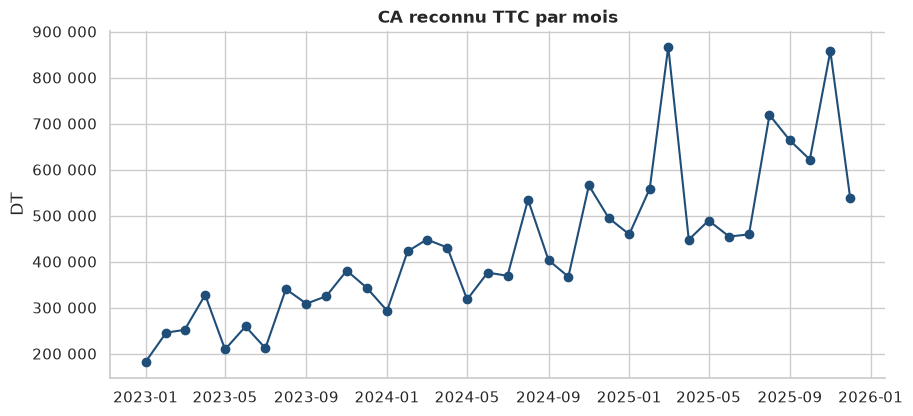

In [5]:
# Évolution mensuelle (pandas sur la vue chargée)
aboutie = cmd[cmd["est_aboutie"]].copy()
aboutie["mois"] = aboutie["date"].dt.to_period("M").dt.to_timestamp()
mensuel = aboutie.groupby("mois").agg(ca_reconnu=("montant_total_ttc", "sum"), commandes=("commande_id", "count"))

fig, ax = plt.subplots()
ax.plot(mensuel.index, mensuel["ca_reconnu"], marker="o", color=cfg.BLEU)
ax.set_title("CA reconnu TTC par mois")
ax.set_ylabel("DT"); cfg.format_milliers(ax)
montrer("Q01_1")

In [6]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(annuel, "Q01_ventes_annuelles")
cfg.exporter_table(mensuel, "Q01_ventes_mensuelles")
print("Tableaux exportés.")

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.eda_q01_ventes_annuelles                      3 lignes
  ✔ ana.eda_q01_ventes_mensuelles                    36 lignes
Tableaux exportés.


> **Lecture.** Le CA reconnu passe de 3,38 M DT (2023) à 5,02 M (2024) puis 7,13 M (2025) : **+48,4 % puis +42,1 %**. La croissance vient surtout du **nombre de commandes** (+42 % puis +40 %), le panier moyen n'augmentant que de 254 à 269 DT (+6 %). **Pour la prévision :** la tendance est forte ; un modèle qui ne la prend pas en compte (simple moyenne, saisonnalité seule) sous-estimera systématiquement 2025.

> ✅ **Verdict : hypothèse confirmée** — le nombre de commandes progresse de 42 % puis 40 %, le panier moyen de 6 % seulement.

### Q2. Y a-t-il une saisonnalité ? Quel est l'effet du Ramadan et des périodes commerciales ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | Pics au Black Friday et autour du Ramadan et de l'Aïd ; ces dates lunaires avancent chaque année. |
| **Indicateurs** | Indice de saisonnalité mensuel, CA moyen par jour par période commerciale |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_date` |
| **Méthode** | pandas |
| **Visualisation** | Barres d'indice ; tableau par période |
| **Lien data mining / ML** | Prévision : variables de calendrier ; retard : périodes de pointe |

Pour comparer des périodes de durées différentes, on raisonne en **CA moyen par jour**.

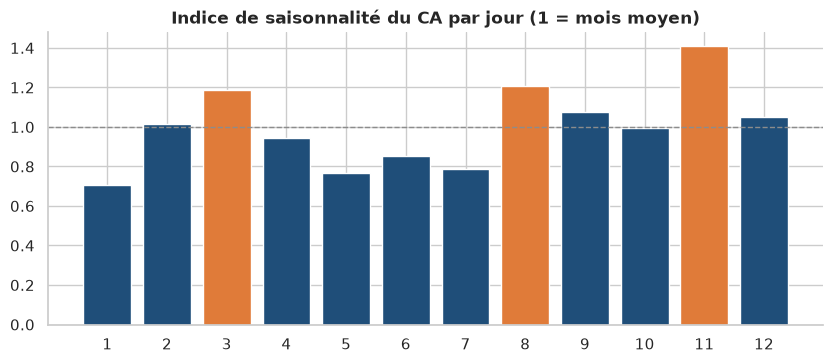

In [7]:
# On rattache chaque commande aboutie à son jour calendaire (attributs : mois, Ramadan, période commerciale)
cal = vues["dim_date"][["date_sk", "mois", "est_ramadan", "periode_commerciale"]]
a = aboutie.merge(cal, left_on="date_commande_sk", right_on="date_sk", how="left", suffixes=("", "_cal"))

# CA par jour, puis moyenne par mois de l'année (toutes années confondues) -> indice de saisonnalité
ca_jour = a.groupby(["date", "mois_cal"])["montant_total_ttc"].sum().reset_index()
indice = ca_jour.groupby("mois_cal")["montant_total_ttc"].mean()
indice = indice / indice.mean()                      # 1 = un mois « moyen »

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(indice.index, indice.values, color=[cfg.ORANGE if v > 1.1 else cfg.BLEU for v in indice.values])
ax.axhline(1, color=cfg.GRIS, lw=1, ls="--")
ax.set_xticks(range(1, 13)); ax.set_title("Indice de saisonnalité du CA par jour (1 = mois moyen)")
montrer("Q02_1")

In [8]:
# CA moyen par jour selon la période commerciale et le Ramadan
jours = vues["dim_date"][(vues["dim_date"]["date_sk"] >= 20230101) & (vues["dim_date"]["date_sk"] <= 20251231)]
ca_par_jour = a.groupby("date_commande_sk")["montant_total_ttc"].sum()
jours = jours.assign(ca=jours["date_sk"].map(ca_par_jour).fillna(0))

periodes = jours.groupby("periode_commerciale").agg(jours=("date_sk", "count"), ca_moyen_jour=("ca", "mean"))
periodes["indice"] = periodes["ca_moyen_jour"] / jours["ca"].mean()
ramadan = jours.groupby("est_ramadan").agg(jours=("date_sk", "count"), ca_moyen_jour=("ca", "mean"))
display(periodes.sort_values("indice", ascending=False))
display(ramadan)

,jours,ca_moyen_jour,indice
periode_commerciale,,,
black_friday,30,39 372.601,2.777
pre_aid_fitr,30,25 093.355,1.770
soldes_ete,93,17 135.453,1.208
ramadan,58,16 618.013,1.172
rentree_scolaire,75,15 571.800,1.098
fin_annee,51,14 549.670,1.026
soldes_hiver,99,14 148.516,0.998
pre_aid_idha,24,14 041.552,0.990
normale,636,11 639.350,0.821


,jours,ca_moyen_jour
est_ramadan,,
False,1008,13 715.298
True,88,19 507.334


In [9]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(periodes, "Q02_ca_par_periode_commerciale")
print("Tableaux exportés.")

  ✔ ana.eda_q02_ca_par_periode_commerciale            9 lignes
Tableaux exportés.


> **Lecture.** La saisonnalité est marquée : **novembre ×1,41** (Black Friday), mars et août ×1,2 ; janvier (×0,71) et mai (×0,77) sont les creux. Les périodes commerciales pèsent fortement : CA par jour ×2,78 pendant le Black Friday, ×1,77 avant l'Aïd el-Fitr, et **+42 % pendant le Ramadan** (19 507 contre 13 715 DT par jour). Le Ramadan avance d'environ 11 jours chaque année (du 23/03 en 2023 au 01/03 en 2025). **Pour la prévision et le retard :** il faut des variables de calendrier (Ramadan, pré-Aïd, Black Friday) et pas seulement le numéro du mois.

> ✅ **Verdict : hypothèse confirmée** — Black Friday ×2,8 par jour, Ramadan +42 %, et les dates lunaires avancent d'environ 11 jours par an.

### Q9. Par quels canaux et modes de paiement les clients achètent-ils ?

| Élément | Détail |
|---|---|
| **Hypothèse à vérifier** | L'application mobile progresse et le paiement à la livraison recule (contrôles CC07 à CC10). |
| **Indicateurs** | Part des commandes par canal et trimestre, par mode de paiement et année, taux d'échec par mode |
| **Vues bi utilisées** | `v_fact_commandes`, `v_dim_canal`, `v_dim_mode_paiement`, `v_fact_paiements` |
| **Méthode** | pandas |
| **Visualisation** | Courbes de parts ; tableaux |
| **Lien data mining / ML** | Churn : variables qui dérivent (part mobile, part paiement à la livraison) |

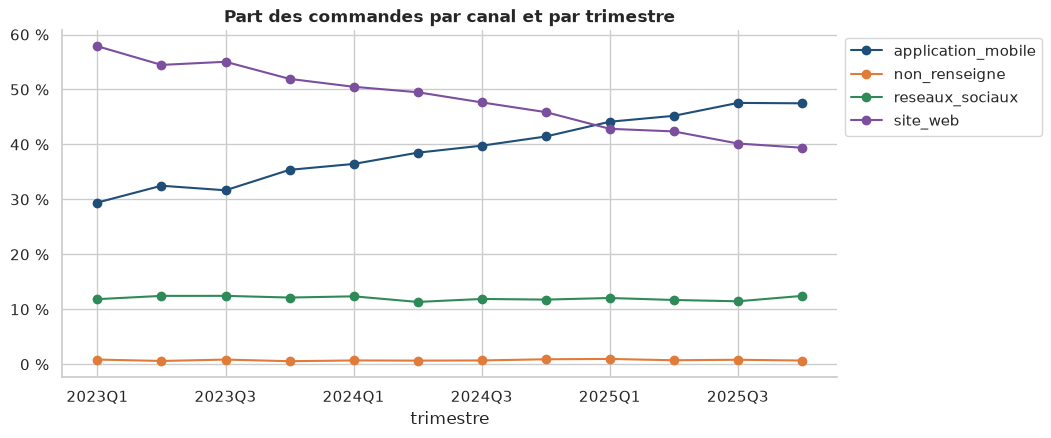

mode_paiement,carte_bancaire,carte_prepayee,paiement_a_la_livraison,portefeuille_mobile,virement
annee,,,,,
2023,0.274,0.064,0.530,0.101,0.031
2024,0.298,0.065,0.497,0.110,0.030
2025,0.317,0.059,0.466,0.128,0.030


,tentatives,taux_reussite,taux_echec
mode_paiement,,,
portefeuille_mobile,8455,0.872,0.128
carte_bancaire,21838,0.876,0.124
carte_prepayee,4452,0.885,0.115
paiement_a_la_livraison,28282,1.000,0.000
virement,1464,1.000,0.000


In [10]:
cmd["trimestre"] = cmd["date"].dt.to_period("Q").astype(str)
part_canal = pd.crosstab(cmd["trimestre"], cmd["canal"], normalize="index")
part_paiement = pd.crosstab(cmd["annee"].astype(int), cmd["mode_paiement"], normalize="index")

fig, ax = plt.subplots()
part_canal.plot(ax=ax, marker="o")
ax.set_title("Part des commandes par canal et par trimestre"); cfg.format_pourcent(ax)
ax.legend(title="", bbox_to_anchor=(1, 1)); montrer("Q09_1")

# Taux d'échec de paiement par mode (tentatives de paiement)
echec = pai.groupby("mode_paiement")["est_reussi"].agg(tentatives="size", taux_reussite="mean")
echec["taux_echec"] = 1 - echec["taux_reussite"]
display(part_paiement)
display(echec.sort_values("taux_echec", ascending=False))

In [11]:
# Export des tableaux de résultats pour les rapports (06_Exports/Tables)
cfg.exporter_table(part_canal, "Q09_parts_canal")
cfg.exporter_table(echec, "Q09_echec_paiement")
print("Tableaux exportés.")

  ✔ ana.eda_q09_parts_canal                          12 lignes
  ✔ ana.eda_q09_echec_paiement                        5 lignes
Tableaux exportés.


> **Lecture.** Le canal se déplace vite : l'**application mobile** passe de 29,4 % des commandes (T1 2023) à 47,5 % (T4 2025), au détriment du site web (57,9 % → 39,4 %). Le **paiement à la livraison** recule (53,0 % → 46,6 %) mais reste le premier mode. Les échecs de paiement (12 à 13 %) ne concernent que les paiements en ligne (carte, portefeuille mobile). **Pour le ML :** `part_mobile` et `part_paiement_livraison` sont des variables qui dérivent dans le temps : leur effet appris en 2023-2024 devra être vérifié en 2025.

> ✅ **Verdict : hypothèse confirmée** — mobile de 29 % à 48 % des commandes, paiement à la livraison de 53 % à 47 %.

## Synthèse du notebook

| N° | Question | Verdict | Constat clé |
|---|---|---|---|
| Q1 | Comment évoluent les ventes entre 2023 et 2025 ? | ✅ Confirmée | le nombre de commandes progresse de 42 % puis 40 %, le panier moyen de 6 % seulement. |
| Q2 | Y a-t-il une saisonnalité ? Quel est l'effet du Ramadan et des périodes commerciales ? | ✅ Confirmée | Black Friday ×2,8 par jour, Ramadan +42 %, et les dates lunaires avancent d'environ 11 jours par an. |
| Q9 | Par quels canaux et modes de paiement les clients achètent-ils ? | ✅ Confirmée | mobile de 29 % à 48 % des commandes, paiement à la livraison de 53 % à 47 %. |

**Ce que ce notebook transmet à la suite :**

- **Prévision des ventes** : tendance forte (+48 % puis +42 %) et saisonnalité liée au Black Friday, au Ramadan et à l'Aïd, dont les dates avancent chaque année → variables de calendrier lunaire indispensables.
- **Churn** : `part_mobile` et `part_paiement_livraison` dérivent dans le temps ; leur effet appris en 2023-2024 devra être vérifié sur 2025.

In [12]:
# Verdicts des hypothèses de ce notebook, enregistrés comme les autres résultats :
#   -> 06_Exports/Tables/EDA_hypotheses_02_EDA_Sales.csv
#   -> table ana.eda_hypotheses de TuniShop_ANALYTICS (lignes de ce notebook seulement, colonne « notebook »)
verdicts = pd.DataFrame([["Q1", "Ventes et produits", "Comment évoluent les ventes entre 2023 et 2025 ?", "La croissance vient surtout du nombre de commandes plutôt que du panier moyen.", "Confirmée", "le nombre de commandes progresse de 42 % puis 40 %, le panier moyen de 6 % seulement."], ["Q2", "Ventes et produits", "Y a-t-il une saisonnalité ? Quel est l'effet du Ramadan et des périodes commerciales ?", "Pics au Black Friday et autour du Ramadan et de l'Aïd ; ces dates lunaires avancent chaque année.", "Confirmée", "Black Friday ×2,8 par jour, Ramadan +42 %, et les dates lunaires avancent d'environ 11 jours par an."], ["Q9", "Canaux et paiements", "Par quels canaux et modes de paiement les clients achètent-ils ?", "L'application mobile progresse et le paiement à la livraison recule (contrôles CC07 à CC10).", "Confirmée", "mobile de 29 % à 48 % des commandes, paiement à la livraison de 53 % à 47 %."]],
                        columns=["question", "theme", "question_metier", "hypothese", "verdict", "constat"])
cfg.exporter_table(verdicts, "EDA_hypotheses_02_EDA_Sales", index=False)
verdicts[["question", "verdict"]]

  ✔ ana.eda_hypotheses                                3 lignes


,question,verdict
0,Q1,Confirmée
1,Q2,Confirmée
2,Q9,Confirmée


In [13]:
# Fin du notebook : on ferme les connexions (DWH et base des résultats)
chargement.fermer_connexion()
publication.fermer_connexion()

Connexion fermée.
